# Notebook dedicated to construct 3D Plots to illustrate the hit Type distribution

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import glob 
import plotly.graph_objects as go

# Useful Function

In [2]:
def magnitude(vector): 
    #Function to Compute the radial position of events
    x = vector[:,0]
    y = vector[:,1]
    z = vector[:,2]

    r = np.sqrt(x**2 + y**2 + z**2)
    r = r.astype(np.float32)
    return r

# Load the Data

In [3]:
fdir = '/home/joankl/data/solars/mc/2p2PPO/electrons/results_npz/resume/resume_npz/'
flist = sorted(glob.glob(fdir + 'e_*MeV_resumed.npz'))

observable_list = ['pmt_db', 'mcid', 'energy_mc', 'pos_mc', 'time_residual_recons', 'hit_type', 'hit_pmt_id', 'dir_mc']

data_dict = {obs_i: [] for obs_i in observable_list}

for file_i in flist:
    np_data = np.load(file_i)

    for obs_i in observable_list:
        data_dict[obs_i].append(np_data[obs_i])

for obs_i in observable_list:
    data_dict[obs_i] = np.concatenate(data_dict[obs_i], axis = 0)

print(data_dict['mcid'].shape)

(14809556,)


## Extract PMT Data Base

The PMT DB is structured as follows: (pmt_id, pos.x, pos.y, pos.z, pmt_type)

In [5]:
pmt_db = data_dict['pmt_db']
pmt_db_id = pmt_db[:,0]
pmt_db_pos_xyz = pmt_db[:,1:4]
pmt_db_type = pmt_db[:,4]

# Data Cuts

1) Apply data cuts
2) Separate hit types

In [6]:
# ========= Data Cuts =========
tres_inf, tres_sup = -4, 20
tres_mask = (data_dict['time_residual_recons'] >= tres_inf) & (data_dict['time_residual_recons'] <= tres_sup)

posr_cut = 5500 # FV Cut
posr_mask = magnitude(data_dict['pos_mc']) <= posr_cut

hit_cher_mask = (data_dict['hit_type'] == 1) # Select Cherenkov Hits 

general_mask = tres_mask & hit_cher_mask & posr_mask

# ========= Select the Data =========

mcid = data_dict['mcid'][general_mask]
energy_mc = data_dict['energy_mc'][general_mask]
pos_mc = data_dict['pos_mc'][general_mask]
hit_pmt_id = data_dict['hit_pmt_id'][general_mask]
dir_mc = data_dict['dir_mc'][general_mask]

hit_pmt_xyz = pmt_db_pos_xyz[hit_pmt_id]

In [7]:
# ========= Separate by events =========
event_start_indices = np.concatenate(([0], np.where(np.diff(mcid) != 0)[0] + 1)) # Array with the indices where an event start (event_start_indices[i]) and ends (event_start_indices[i+1]) 

hit_pmt_xyz_ev = np.split(hit_pmt_xyz, event_start_indices[1:])
hit_pmt_id_ev = np.split(hit_pmt_id, event_start_indices[1:])
energy_ev = energy_mc[event_start_indices]
pos_mc_ev = pos_mc[event_start_indices]
posr_mc_ev = magnitude(pos_mc_ev)
dir_mc_ev = dir_mc[event_start_indices]

# Plots

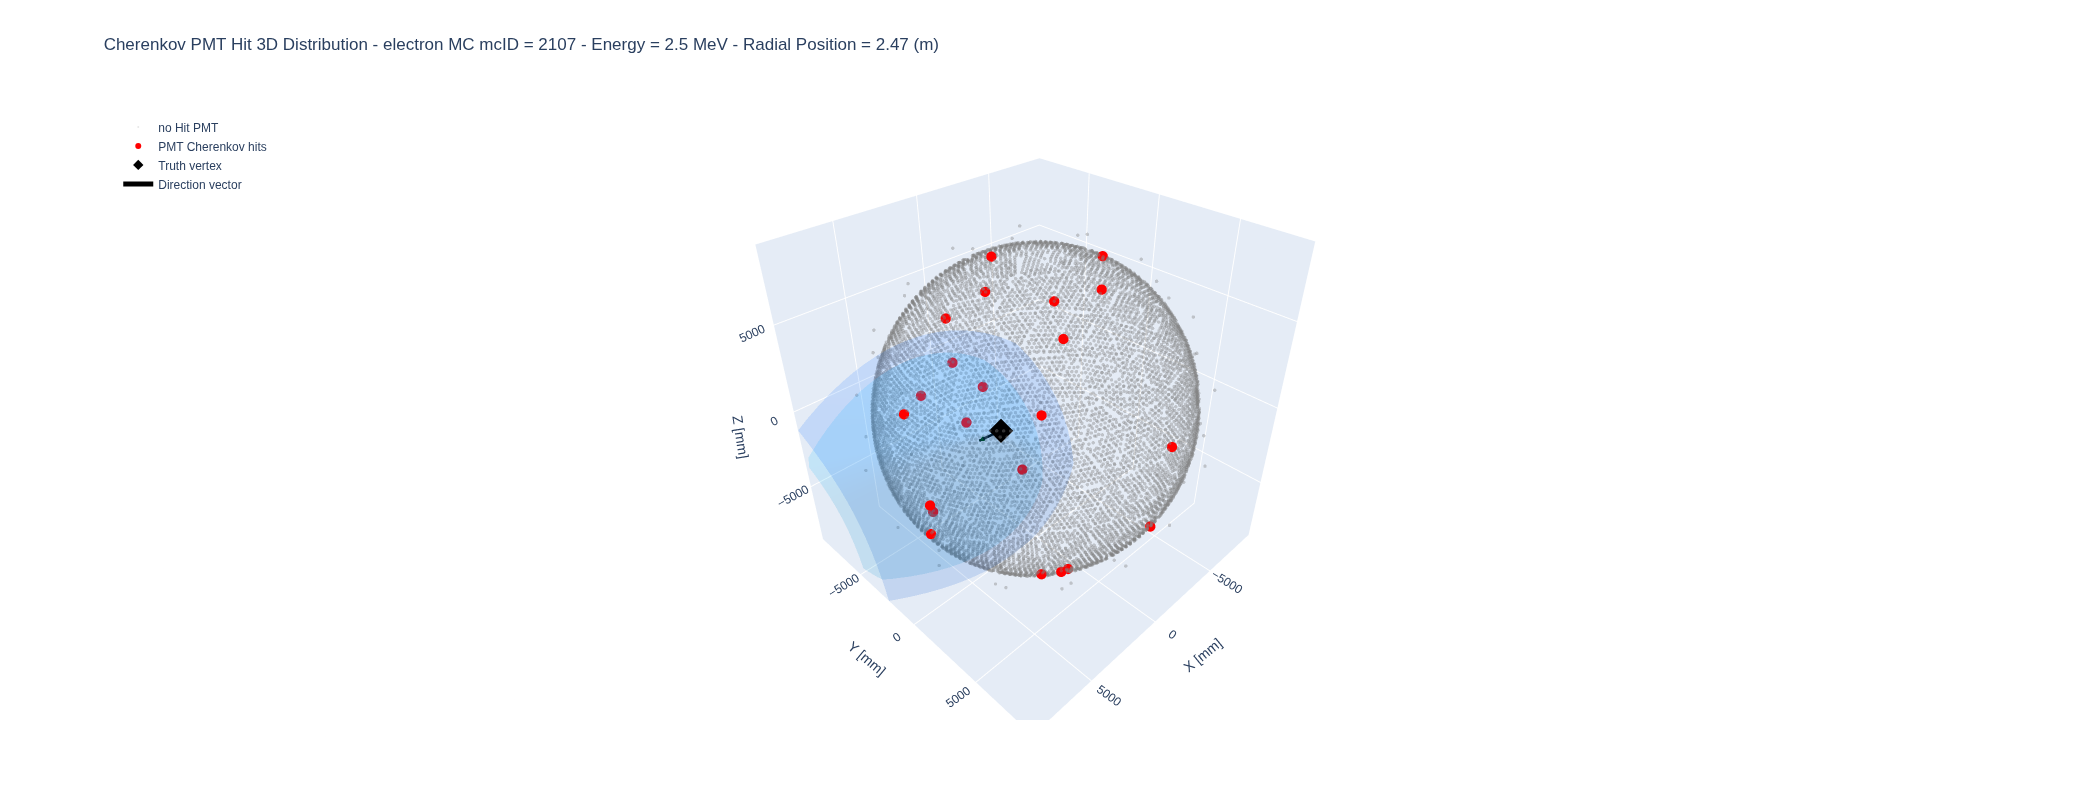

In [18]:
random_evtID = np.random.randint(0, len(energy_ev))  # Random number to pick a random event to plot
#random_evtID = 4383

# ======= Preparing the Data =======
hit_pmt_xyz_ev_i = hit_pmt_xyz_ev[random_evtID]
hit_pmt_id_ev_i = hit_pmt_id_ev[random_evtID]
energy_ev_i = energy_ev[random_evtID]
pos_mc_ev_i = pos_mc_ev[random_evtID]
posr_mc_ev_i = posr_mc_ev[random_evtID]
dir_mc_ev_i = dir_mc_ev[random_evtID]

# Hit coordinates
x = hit_pmt_xyz_ev_i[:, 0]
y = hit_pmt_xyz_ev_i[:, 1]
z = hit_pmt_xyz_ev_i[:, 2]

# PMT DB coordinates: Remove PMT Type 2
no_hit_mask = ~np.isin(pmt_db_id, np.unique(hit_pmt_id_ev_i))
no_hit_xyz = pmt_db_pos_xyz[no_hit_mask]

# Vertex coordinates
vx, vy, vz = pos_mc_ev_i

# Direction Vector configuration
arrow_length = 2500
dx, dy, dz = dir_mc_ev_i * arrow_length

# ====== Cherenkov Cones Definitions ======
# Two cones: Define the opening angle between the cone surface and the direction of the event
cos_theta_inner = 0.75  
cos_theta_outer = 0.65  

theta_inner = np.arccos(cos_theta_inner)
theta_outer = np.arccos(cos_theta_outer)

# Vector orthogonal to the cone base
arbitrary = np.array([0.0, 0.0, 1.0])
if np.abs(np.dot(dir_mc_ev_i, arbitrary)) > 0.99:
    arbitrary = np.array([0.0, 1.0, 0.0])

v1 = np.cross(dir_mc_ev_i, arbitrary)
v1 /= np.linalg.norm(v1)
v2 = np.cross(dir_mc_ev_i, v1)

# Altura del cono hasta la superficie de los PMTs (~8500 mm)
cone_height = 8500 

# Grid to construct the cone surface
h_grid, phi_grid = np.meshgrid(np.linspace(0, cone_height, 30), np.linspace(0, 2 * np.pi, 60))

def generate_cone_surface(theta):
    r_grid = h_grid * np.tan(theta)
    c_x = np.zeros(h_grid.shape)
    c_y = np.zeros(h_grid.shape)
    c_z = np.zeros(h_grid.shape)
    
    for i in range(h_grid.shape[0]):
        for j in range(h_grid.shape[1]):
            h = h_grid[i, j]
            r = r_grid[i, j]
            phi = phi_grid[i, j]
            pt = np.array([vx, vy, vz]) + h * dir_mc_ev_i + r * (np.cos(phi) * v1 + np.sin(phi) * v2)
            c_x[i, j] = pt[0]
            c_y[i, j] = pt[1]
            c_z[i, j] = pt[2]
    return c_x, c_y, c_z

# Generate the cooordinates of the cone surfaces
cone_x_in, cone_y_in, cone_z_in = generate_cone_surface(theta_inner)
cone_x_out, cone_y_out, cone_z_out = generate_cone_surface(theta_outer)


# ====== Figure ======
fig = go.Figure()

# No hit PMTs
fig.add_trace(go.Scatter3d(x=no_hit_xyz[:, 0], y=no_hit_xyz[:, 1], z=no_hit_xyz[:, 2], mode='markers', 
                           name='no Hit PMT', marker=dict(size=2, opacity=0.15, color='gray'), hoverinfo='skip'))

# Inner Cone
fig.add_trace(go.Surface(x=cone_x_in, y=cone_y_in, z=cone_z_in, colorscale=[[0, 'rgba(0, 180, 255, 0.15)'], [1, 'rgba(0, 180, 255, 0.15)']], 
                         showscale=False, name=r'Inner Cone ($\cos\\theta=0.75$)', hoverinfo='skip'))

# External Cone
fig.add_trace(go.Surface(x=cone_x_out, y=cone_y_out, z=cone_z_out, colorscale=[[0, 'rgba(0, 100, 255, 0.15)'], [1, 'rgba(0, 100, 255, 0.15)']],
                         showscale=False, name=r'Outer Cone ($\cos\\theta=0.60$)', hoverinfo='skip'))

# Hit PMTs (Cherenkov Hits) 
fig.add_trace(go.Scatter3d(x=x, y=y, z=z, mode='markers', name='PMT Cherenkov hits', marker=dict(size=6, opacity=1, color='red'),
                           hovertemplate='X: %{x:.2f}<br>Y: %{y:.2f}<br>Z: %{z:.2f}<extra>PMT hit</extra>'))

# Event Vertex
fig.add_trace(go.Scatter3d(x=[vx], y=[vy], z=[vz], mode='markers', name='Truth vertex', marker=dict(size=8, color='black', symbol='diamond')))

# 6. Tail of the vector
fig.add_trace(go.Scatter3d(x=[vx, vx + dx], y=[vy, vy + dy], z=[vz, vz + dz], mode='lines', name='Direction vector',
    line=dict(color='black', width=5), showlegend=True, hoverinfo='skip'))

# 7. Vector head_arrow as a cone
fig.add_trace(go.Cone(x=[vx + dx], y=[vy + dy], z=[vz + dz], u=[dx], v=[dy], w=[dz], name='Direction tip', 
    colorscale=[[0, 'green'], [1, 'black']], showscale=False, sizemode='absolute', sizeref=arrow_length * 0.2, anchor='tip', showlegend=False))

# Layout
fig.update_layout(title=fr'Acceptance Window Cones ($\cos\\theta \in [0.60, 0.75]$)<br>electron MC - mcID = {random_evtID} - Energy = {energy_ev_i} MeV', 
                  scene=dict(xaxis_title='X [mm]', xaxis=dict(nticks=4, range=[-9000, 9000]),
                             yaxis_title='Y [mm]', yaxis=dict(nticks=4, range=[-9000, 9000]),
                             zaxis_title='Z [mm]', zaxis=dict(nticks=4, range=[-9000, 9000]), aspectmode='data'), 
                  width=900, height=800, legend=dict(x=0.02, y=0.98))

fig.update_layout(title=f'Cherenkov PMT Hit 3D Distribution - electron MC' + '\n' + rf'mcID = {random_evtID} - Energy = {energy_ev_i} MeV - Radial Position = {posr_mc_ev_i/1000:.2f} (m)', 
                  scene=dict(xaxis_title='X [mm]', xaxis = dict(nticks=4, range=[-9000, 9000]),
                             yaxis_title='Y [mm]', yaxis = dict(nticks=4, range=[-9000, 9000]),
                             zaxis_title='Z [mm]', zaxis = dict(nticks=4, range=[-9000, 9000]), aspectmode='data'), 
                  width=900, height=800, legend=dict(x=0.02,y=0.98),)


fig.show()